In [ ]:
import csv
import numpy as np
from sklearn.datasets import fetch_openml

print("Fetching Golub Leukemia dataset from OpenML repository...")
leukemia = fetch_openml(name='leukemia', version=1, as_frame=False)

# X_raw: (72 patients, 7129 genes)
# y_raw: array of labels ('ALL' or 'AML')
X_raw = leukemia.data.astype(float)
y_raw = leukemia.target

print(f"Data retrieved successfully!")
print(f"Matrix Dimensions: {X_raw.shape[0]} patients x {X_raw.shape[1]} genes")
print(f"Classes present: {np.unique(y_raw)}")


with open("leukemia_data.csv", mode="w", newline="") as f:
    writer = csv.writer(f)

    header = [f"Gene_{i+1}" for i in range(X_raw.shape[1])]
    writer.writerow(header)
    for patient_vector in X_raw:
        writer.writerow(patient_vector)

with open("leukemia_labels.csv", mode="w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Patient_ID", "Diagnosis"])
    for idx, label in enumerate(y_raw):
        writer.writerow([idx + 1, label])

print("-> Generated 'leukemia_data.csv' and 'leukemia_labels.csv' successfully!")

Fetching Golub Leukemia dataset from OpenML repository...
Data retrieved successfully!
Matrix Dimensions: 72 patients x 7129 genes
Classes present: ['ALL' 'AML']
-> Generated 'leukemia_data.csv' and 'leukemia_labels.csv' successfully!


In [ ]:
gene_matrix = []
with open("leukemia_data.csv", mode="r") as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
              gene_matrix.append([float(val) for val in row])

labels_list = []
with open("leukemia_labels.csv", mode="r") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        labels_list.append(row[1])

X = np.array(gene_matrix)
labels = np.array(labels_list)

print("--- DATA LOADED WITH CSV MODULE ---")
print(f"NumPy Matrix Shape (m x n): {X.shape}")
print(f"Total Patients (m): {X.shape[0]}")
print(f"Total Genes per Patient (n): {X.shape[1]}")
print(f"Class breakdown: ALL = {np.sum(labels == 'ALL')}, AML = {np.sum(labels == 'AML')}")

--- DATA LOADED WITH CSV MODULE ---
NumPy Matrix Shape (m x n): (72, 7129)
Total Patients (m): 72
Total Genes per Patient (n): 7129
Class breakdown: ALL = 47, AML = 25


Raw gene expression values contain baseline cell activity shared by all humans. Mean-centering shifts the origin to the dataset's center of mass by subtracting the mean gene vector  $\vec{\mu}$ , ensuring that positive values indicate up-regulation and negative values indicate down-regulation.

Because the number of genes ($n = 7,129$) is much larger than the number of patients ($m = 72$), a full gene-to-gene covariance matrix ($7,129 \times 7,129$) is computationally expensive. Instead, we compute the inner-product patient covariance matrix ($38 \times 38$) using dot products:

In [ ]:
mu = np.mean(X, axis=0)
X_c = X - mu
m = X_c.shape[0]
patient_cov = (1 / (m - 1)) * np.dot(X_c, X_c.T)

print("--- STEP 2: CENTERING  ---")
print(f"Mean vector shape: {mu.shape}")
print(f"Centered Matrix X_c shape: {X_c.shape}")
print(f"Verify zero-mean (mean of centered data ~ 0): {np.allclose(np.mean(X_c, axis=0), 0)}")
print(f"Patient Covariance (Gram) Matrix shape: {patient_cov.shape}")
print(f"Is Covariance Matrix Symmetric? {np.allclose(patient_cov, patient_cov.T)}")

--- STEP 2: CENTERING  ---
Mean vector shape: (7129,)
Centered Matrix X_c shape: (72, 7129)
Verify zero-mean (mean of centered data ~ 0): True
Patient Covariance (Gram) Matrix shape: (72, 72)
Is Covariance Matrix Symmetric? True


SVD
To decompose the high-dimensional, centered matrix into three distinct components: patient coordinate projections ($U$), singular value scale factors ($\Sigma$), and orthogonal principal axes ($V^T$).

To quantify the proportion of total variance captured along each orthogonal axis and prove that a small subset of components accounts for the vast majority of biological variation.

--- STEP 3: SVD & VARIANCE ANALYSIS ---
Shape of U (Patient projections): (72, 72)
Number of Singular Values in S: 72
Shape of V^T (Gene basis axes): (72, 7129)
Top 3 Singular Values: [265696.92 204643.24 176496.18]
Variance explained by Component 1: 17.43%
Variance explained by Component 2: 10.34%
Total variance captured by first 2 axes: 27.77%


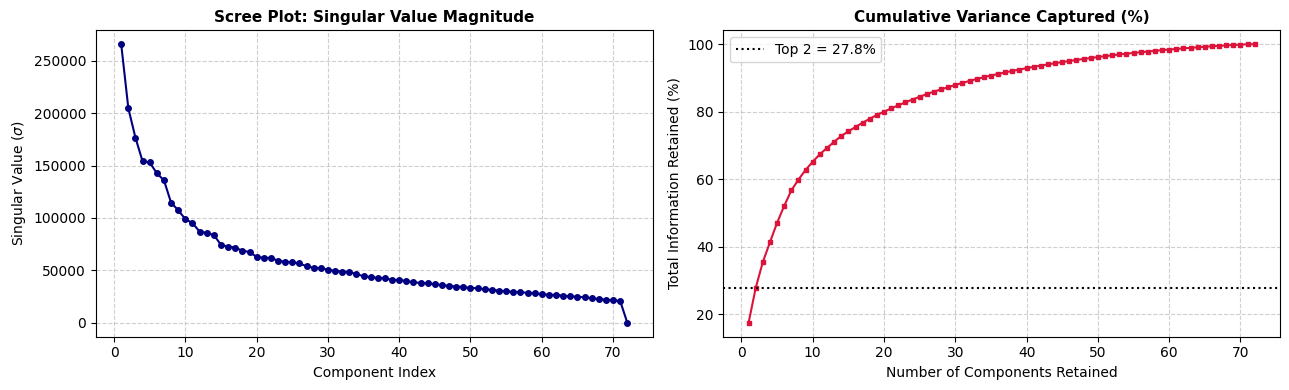

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Compute the Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(X_c, full_matrices=False)

# 2. Calculate the variance explained
variance_explained = (S ** 2) / np.sum(S ** 2)
cumulative_variance = np.cumsum(variance_explained) * 100

print("--- STEP 3: SVD & VARIANCE ANALYSIS ---")
print(f"Shape of U (Patient projections): {U.shape}")
print(f"Number of Singular Values in S: {len(S)}")
print(f"Shape of V^T (Gene basis axes): {Vt.shape}")
print(f"Top 3 Singular Values: {S[:3].round(2)}")
print(f"Variance explained by Component 1: {variance_explained[0]*100:.2f}%")
print(f"Variance explained by Component 2: {variance_explained[1]*100:.2f}%")
print(f"Total variance captured by first 2 axes: {cumulative_variance[1]:.2f}%")

# 3. Plot Scree Plot & Cumulative Variance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))


ax1.plot(range(1, len(S) + 1), S, 'o-', color='navy', linewidth=1.5, markersize=4)
ax1.set_title("Scree Plot: Singular Value Magnitude", fontsize=11, fontweight='bold')
ax1.set_xlabel("Component Index")
ax1.set_ylabel(r"Singular Value ($\sigma$)")
ax1.grid(True, linestyle='--', alpha=0.6)


ax2.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 's-', color='crimson', linewidth=1.5, markersize=3)
ax2.axhline(y=cumulative_variance[1], color='black', linestyle=':', label=f'Top 2 = {cumulative_variance[1]:.1f}%')
ax2.set_title("Cumulative Variance Captured (%)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Number of Components Retained")
ax2.set_ylabel("Total Information Retained (%)")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Projection

To project each patient's high-dimensional centered vector $\vec{x}_i \in \mathbb{R}^{7129}$ onto the low-dimensional orthonormal basis spanned by the top two right singular vectors $\vec{v}_1, \vec{v}_2 \in \mathbb{R}^{7129}$:

Generates a 2D coordinate matrix $Z \in \mathbb{R}^{72 \times 2}$

--- STEP 4: ORTHOGONAL PROJECTION ---
Original Centered Data shape: (72, 7129)
Projection Basis Matrix V_k shape: (7129, 2)
Projected Subspace Coordinates Z shape: (72, 2)
First 3 patients in 2D space (PC1, PC2):
  Patient 1 (ALL): PC1 = -12371.34, PC2 = -16505.72
  Patient 2 (ALL): PC1 = -37565.87, PC2 = 57.61
  Patient 3 (ALL): PC1 = -19116.37, PC2 = -18216.30


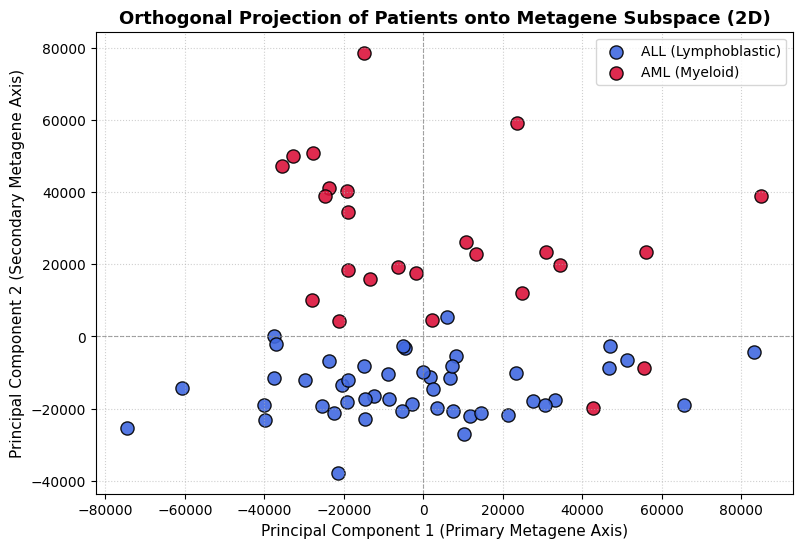

In [ ]:
k = 2
V_k = Vt[:k, :].T
Z = np.dot(X_c, V_k)
print("--- STEP 4: ORTHOGONAL PROJECTION ---")
print(f"Original Centered Data shape: {X_c.shape}")
print(f"Projection Basis Matrix V_k shape: {V_k.shape}")
print(f"Projected Subspace Coordinates Z shape: {Z.shape}")
print("First 3 patients in 2D space (PC1, PC2):")
for i in range(3):
    print(f"  Patient {i+1} ({labels[i]}): PC1 = {Z[i, 0]:.2f}, PC2 = {Z[i, 1]:.2f}")


plt.figure(figsize=(9, 6))

mask_all = (labels == 'ALL')
mask_aml = (labels == 'AML')

plt.scatter(Z[mask_all, 0], Z[mask_all, 1], c='royalblue', edgecolors='black', s=90, label='ALL (Lymphoblastic)', alpha=0.9)
plt.scatter(Z[mask_aml, 0], Z[mask_aml, 1], c='crimson', edgecolors='black', s=90, label='AML (Myeloid)', alpha=0.9)

plt.axhline(0, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8, alpha=0.7)

plt.title("Orthogonal Projection of Patients onto Metagene Subspace (2D)", fontsize=13, fontweight='bold')
plt.xlabel("Principal Component 1 (Primary Metagene Axis)", fontsize=11)
plt.ylabel("Principal Component 2 (Secondary Metagene Axis)", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

The first right singular vector $\vec{v}_1 \in \mathbb{R}^{7129}$ defines the primary metagene axis that maximally separates ALL and AML patient classes.   By evaluating the absolute magnitude of the entries in $\vec{v}_1$, we determine which specific original genes contribute most heavily to this linear combination, filtering out biological background noise.   

--- STEP 5: TOP 10 CANCER BIOMARKER GENES ---
Rank   Gene Name       Weight (Loading)   Impact (|Weight|)
-------------------------------------------------------
#1     Gene_5710       0.35239            0.35239
#2     Gene_19         0.31355            0.31355
#3     Gene_5711       0.23487            0.23487
#4     Gene_1222       0.21045            0.21045
#5     Gene_5997       0.19625            0.19625
#6     Gene_5229       0.18373            0.18373
#7     Gene_5058       0.17742            0.17742
#8     Gene_1868       0.16143            0.16143
#9     Gene_4652       0.13072            0.13072
#10    Gene_5199       0.12453            0.12453


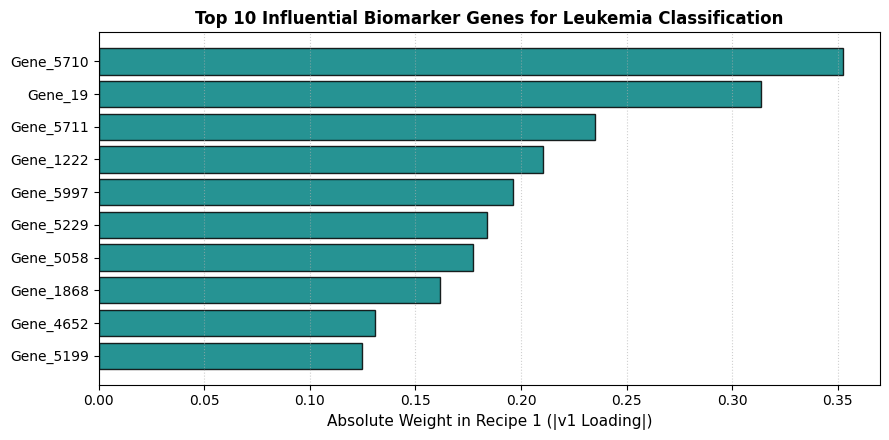

In [ ]:
recipe_1_weights = Vt[0, :]
absolute_weights = np.abs(recipe_1_weights)
top_10_indices = np.argsort(absolute_weights)[-10:][::-1]
print("--- STEP 5: TOP 10 CANCER BIOMARKER GENES ---")
print(f"{'Rank':<6} {'Gene Name':<15} {'Weight (Loading)':<18} {'Impact (|Weight|)'}")
print("-" * 55)

top_gene_names = []
top_gene_scores = []

for rank, idx in enumerate(top_10_indices, 1):
    gene_name = f"Gene_{idx + 1}"
    weight = recipe_1_weights[idx]
    magnitude = absolute_weights[idx]

    top_gene_names.append(gene_name)
    top_gene_scores.append(magnitude)

    print(f"#{rank:<5} {gene_name:<15} {weight:<18.5f} {magnitude:.5f}")

plt.figure(figsize=(9, 4.5))
y_positions = range(len(top_gene_names))

plt.barh(y_positions, top_gene_scores[::-1], color='teal', edgecolor='black', alpha=0.85)
plt.yticks(y_positions, top_gene_names[::-1], fontsize=10)
plt.xlabel("Absolute Weight in Recipe 1 (|v1 Loading|)", fontsize=11)
plt.title("Top 10 Influential Biomarker Genes for Leukemia Classification", fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

For prediction

--- STEP 6: GEOMETRIC DIAGNOSIS TOOL ---
ALL Cluster Center (PC1, PC2): (-1960.92, -14225.66)
AML Cluster Center (PC1, PC2): (3686.53, 26744.23)

=== Diagnosis Report for Patient 1 (Actual: ALL) ===
2D Coordinates (PC1, PC2): (-12371.34, -16505.72)
Distance to ALL Center: 10657.18
Distance to AML Center: 46134.74
Result: ALL (Acute Lymphoblastic Leukemia)



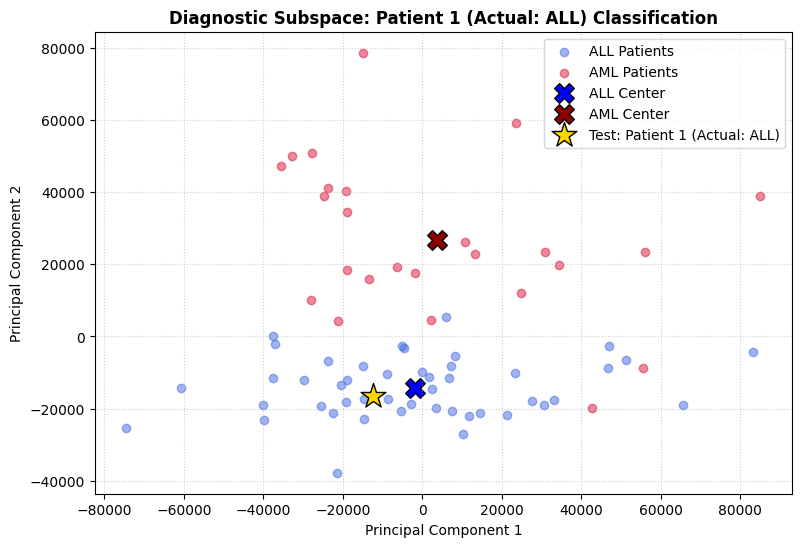

In [ ]:
centroid_all = np.mean(Z[labels == 'ALL'], axis=0)
centroid_aml = np.mean(Z[labels == 'AML'], axis=0)

try:
    _ = X_raw
except NameError:
    X_raw = X
mean_gene_expression = np.mean(X_raw, axis=0)

print("--- STEP 6: GEOMETRIC DIAGNOSIS TOOL ---")
print(f"ALL Cluster Center (PC1, PC2): ({centroid_all[0]:.2f}, {centroid_all[1]:.2f})")
print(f"AML Cluster Center (PC1, PC2): ({centroid_aml[0]:.2f}, {centroid_aml[1]:.2f})\n")

def diagnose_patient(patient_gene_data, patient_id="Unknown Patient"):
    """
    Takes 7,129 raw gene readings of a patient,
    projects them to 2D, measures Euclidean distance to centroids,
    and returns a diagnosis.
    """
    # Step A: Center using the mean of the training data
    centered_sample = patient_gene_data - mean_gene_expression

    # Step B: Project into 2D subspace using V_k
    z_new = np.dot(centered_sample, V_k)

    # Step C: Calculate Euclidean Distance to each cluster center
    dist_to_all = np.linalg.norm(z_new - centroid_all)
    dist_to_aml = np.linalg.norm(z_new - centroid_aml)

    # Step D: Assign class based on minimum distance
    if dist_to_all < dist_to_aml:
        prediction = "ALL (Acute Lymphoblastic Leukemia)"
    else:
        prediction = "AML (Acute Myeloid Leukemia)"

    print(f"=== Diagnosis Report for {patient_id} ===")
    print(f"2D Coordinates (PC1, PC2): ({z_new[0]:.2f}, {z_new[1]:.2f})")
    print(f"Distance to ALL Center: {dist_to_all:.2f}")
    print(f"Distance to AML Center: {dist_to_aml:.2f}")
    print(f"Result: {prediction}\n")

    # Step E: Visualize where the patient lands
    plt.figure(figsize=(9, 6))
    plt.scatter(Z[mask_all, 0], Z[mask_all, 1], c='royalblue', alpha=0.5, label='ALL Patients')
    plt.scatter(Z[mask_aml, 0], Z[mask_aml, 1], c='crimson', alpha=0.5, label='AML Patients')

    # Plot centroids
    plt.scatter(centroid_all[0], centroid_all[1], c='blue', marker='X', s=200, edgecolors='black', label='ALL Center')
    plt.scatter(centroid_aml[0], centroid_aml[1], c='darkred', marker='X', s=200, edgecolors='black', label='AML Center')

    # Plot test patient
    plt.scatter(z_new[0], z_new[1], c='gold', marker='*', s=350, edgecolors='black', label=f'Test: {patient_id}')

    plt.title(f"Diagnostic Subspace: {patient_id} Classification", fontsize=12, fontweight='bold')
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend(frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

test_index = 0
diagnose_patient(X_raw[test_index], patient_id=f"Patient {test_index+1} (Actual: {labels[test_index]})")